In [1]:
import numpy as np
from netCDF4 import Dataset
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
import matplotlib.ticker as mticker
from matplotlib import colors

import matplotlib.gridspec as gridspec
import cartopy
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.crs as ccrs
import iris.analysis.cartography

import iris
import iris.quickplot as qplt 
import iris.plot as iplt
iris.FUTURE.netcdf_promote=True
import iris.coord_categorisation

from iris.analysis import stats
from iris.analysis import maths

from iris.coords import DimCoord

/apps/developers/compilers/canopy3/2.1.3/1/bit-64/Canopy/edm/envs/User/lib/python3.5/site-packages/matplotlib/ticker.py:1693: UserWarning: Steps argument should be a sequence of numbers
increasing from 1 to 10, inclusive. Behavior with
values outside this range is undefined, and will
raise a ValueError in future versions of mpl.
  warnings.warn('Steps argument should be a sequence of numbers\n'


### Open GMOC, AMOC and IPMOC

In [2]:
## GMOC PI
path = '/nfs/hera1/ee22kvcs/PMIP4/'
path2 = '/nfs/hera1/ee22kvcs/KCM/'
models = [ 'ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
names_models_pi = ['GMOC_ty_trans_Omon_ACCESS-ESM1-5_piControl_r1i1p1f1_gn_100yr_mean.nc',
                   'GMOC_xpzed_pi_pg_5021-5120_ann_mean.nc',
                   'msftyz_Omon_IPSL-CM6A-LR_piControl_r1i2p1f1_gn_2000_2099_100_yr_mean.nc',
                   'H0K_tm_4901_5000_moc.nc',
                   'msftmz_Omon_MIROC-ES2L_piControl_r1i1p1f2_gr_225001-234912_100yr_mean.nc',
                   'mmflxmld_NBF1850OC_f19_tn11_02.micom.hy.1600_1699_100yr_mean.nc',
                   'msftmz_Omon_NorESM2-LM_piControl_r1i1p1f1_grz_200101-210012_100yr_mean.nc',]

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'ty_trans'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'field704'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'msftyz'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'zomsfglo'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'msftmz'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'mmflxd'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'msftmz')]

PI_GMOC_models = []
for i in range(np.size(models)):
    if i == 3:
        uploaded_cubes = iris.load_cube(path2+names_models_pi[i], constraints[i])
    else:
        uploaded_cubes = iris.load_cube(path+names_models_pi[i], constraints[i])
    uploaded_cubes2 = iris.util.squeeze(uploaded_cubes)
    PI_GMOC_models.append(uploaded_cubes2)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

In [3]:
## GMOC LIG
path = '/nfs/hera1/ee22kvcs/PMIP4/'
path2 = '/nfs/hera1/ee22kvcs/KCM/'
models = [ 'ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
names_models_lig = ['GMOC_ty_trans_Omon_ACCESS-ESM1-5_lig127k_r1i1p1f1_gn_100101-110012_100yr_mean.nc',
                   'GMOC_xpzeco_lig_pg_6651-6750_ann_mean.nc',
                   'msftyz_Omon_IPSL-CM6A-LR_lig127k_r1i1p1f1_gn_2300-2399_100_yr_mean.nc',
                   'E7C_tm_4901_5000_moc.nc',
                   'msftmz_Omon_MIROC-ES2L_lig127k_r1i1p1f2_gr_330001-339912_100yr_mean.nc',
                   'mmflxmld_NBF1850OC_f19_tn11_01_127ka.micom.hy.1600_1699_100yr_mean.nc',
                   'msftmz_Omon_NorESM2-LM_lig127k_r1i1p1f1_grz_210101-220012_100yr_mean.nc',
                   ]

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'ty_trans'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'field704'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'msftyz'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'zomsfglo'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'msftmz'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'mmflxd'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'msftmz')]

LIG_GMOC_models = []
for i in range(np.size(models)):
    if i == 3:
        uploaded_cubes = iris.load_cube(path2+names_models_lig[i], constraints[i])
    else:
        uploaded_cubes = iris.load_cube(path+names_models_lig[i], constraints[i])
    uploaded_cubes2 = iris.util.squeeze(uploaded_cubes)
    LIG_GMOC_models.append(uploaded_cubes2)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

In [4]:
## AMOC PI
path = '/nfs/hera1/ee22kvcs/PMIP4/'
path2 = '/nfs/hera1/ee22kvcs/KCM/'
models = [ 'ACCESS-ESM1-5', 'HadCM3', 'KCM']
names_models_pi = ['AMOC_ty_trans_Omon_ACCESS-ESM1-5_piControl_r1i1p1f1_gn_100yr_mean.nc',
                   'AMOC_xpzed_pi_pg_5021-5120_ann_mean.nc',
                   #'msftyz_Omon_IPSL-CM6A-LR_piControl_r1i2p1f1_gn_2000_2099_100_yr_mean.nc',
                   'H0K_tm_4901_5000_moc.nc',
                   #'msftmz_Omon_MIROC-ES2L_piControl_r1i1p1f2_gr_225001-234912_100yr_mean.nc',
                   #'mmflxmld_NBF1850OC_f19_tn11_02.micom.hy.1600_1699_100yr_mean.nc',
                   #'msftmz_Omon_NorESM2-LM_piControl_r1i1p1f1_grz_200101-210012_100yr_mean.nc',
                  ]

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'ty_trans'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'unknown'),
               #iris.Constraint(cube_func=lambda cube: cube.var_name == 'msftyz'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'zomsfatl'),
               #iris.Constraint(cube_func=lambda cube: cube.var_name == 'msftmz'),
               #iris.Constraint(cube_func=lambda cube: cube.var_name == 'mmflxd'),
               #iris.Constraint(cube_func=lambda cube: cube.var_name == 'msftmz')
              ]

PI_AMOC_models = []
for i in range(np.size(models)):
    if i == 2:
        uploaded_cubes = iris.load_cube(path2+names_models_pi[i], constraints[i])
    else:
        uploaded_cubes = iris.load_cube(path+names_models_pi[i], constraints[i])
    uploaded_cubes2 = iris.util.squeeze(uploaded_cubes)
    PI_AMOC_models.append(uploaded_cubes2)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

In [5]:
## AMOC LIG
path = '/nfs/hera1/ee22kvcs/PMIP4/'
path2 = '/nfs/hera1/ee22kvcs/KCM/'
models = [ 'ACCESS-ESM1-5', 'HadCM3', 'KCM']
names_models_lig = ['AMOC_ty_trans_Omon_ACCESS-ESM1-5_lig127k_r1i1p1f1_gn_100101-110012_100yr_mean.nc',
                   'AMOC_xpzeco_lig_pg_6651-6750_ann_mean.nc',
                   #'msftyz_Omon_IPSL-CM6A-LR_piControl_r1i2p1f1_gn_2000_2099_100_yr_mean.nc',
                   'E7C_tm_4901_5000_moc.nc',
                   #'msftmz_Omon_MIROC-ES2L_piControl_r1i1p1f2_gr_225001-234912_100yr_mean.nc',
                   #'mmflxmld_NBF1850OC_f19_tn11_02.micom.hy.1600_1699_100yr_mean.nc',
                   #'msftmz_Omon_NorESM2-LM_piControl_r1i1p1f1_grz_200101-210012_100yr_mean.nc',
                  ]

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'ty_trans'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'unknown'),
               #iris.Constraint(cube_func=lambda cube: cube.var_name == 'msftyz'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'zomsfatl'),
               #iris.Constraint(cube_func=lambda cube: cube.var_name == 'msftmz'),
               #iris.Constraint(cube_func=lambda cube: cube.var_name == 'mmflxd'),
               #iris.Constraint(cube_func=lambda cube: cube.var_name == 'msftmz')
              ]

LIG_AMOC_models = []
for i in range(np.size(models)):
    if i == 2:
        uploaded_cubes = iris.load_cube(path2+names_models_lig[i], constraints[i])
    else:
        uploaded_cubes = iris.load_cube(path+names_models_lig[i], constraints[i])
    uploaded_cubes2 = iris.util.squeeze(uploaded_cubes)
    LIG_AMOC_models.append(uploaded_cubes2)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

In [6]:
## IPMOC PI
path = '/nfs/hera1/ee22kvcs/PMIP4/'
path2 = '/nfs/hera1/ee22kvcs/KCM/'
models = [ 'ACCESS-ESM1-5', 'HadCM3', 'KCM']
names_models_pi = ['IPMOC_ty_trans_Omon_ACCESS-ESM1-5_piControl_r1i1p1f1_gn_100yr_mean.nc',
                   'IPMOC_xpzed_pi_pg_5021-5120_ann_mean.nc',
                   #'msftyz_Omon_IPSL-CM6A-LR_piControl_r1i2p1f1_gn_2000_2099_100_yr_mean.nc',
                   'H0K_tm_4901_5000_moc.nc',
                   #'msftmz_Omon_MIROC-ES2L_piControl_r1i1p1f2_gr_225001-234912_100yr_mean.nc',
                   #'mmflxmld_NBF1850OC_f19_tn11_02.micom.hy.1600_1699_100yr_mean.nc',
                   #'msftmz_Omon_NorESM2-LM_piControl_r1i1p1f1_grz_200101-210012_100yr_mean.nc',
                  ]

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'ty_trans'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'unknown'),
               #iris.Constraint(cube_func=lambda cube: cube.var_name == 'msftyz'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'zomsfinp'),
               #iris.Constraint(cube_func=lambda cube: cube.var_name == 'msftmz'),
               #iris.Constraint(cube_func=lambda cube: cube.var_name == 'mmflxd'),
               #iris.Constraint(cube_func=lambda cube: cube.var_name == 'msftmz')
              ]

PI_IPMOC_models = []
for i in range(np.size(models)):
    if i == 2:
        uploaded_cubes = iris.load_cube(path2+names_models_pi[i], constraints[i])
    else:
        uploaded_cubes = iris.load_cube(path+names_models_pi[i], constraints[i])
    uploaded_cubes2 = iris.util.squeeze(uploaded_cubes)
    PI_IPMOC_models.append(uploaded_cubes2)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

In [7]:
## IPMOC LIG
path = '/nfs/hera1/ee22kvcs/PMIP4/'
path2 = '/nfs/hera1/ee22kvcs/KCM/'
models = [ 'ACCESS-ESM1-5', 'HadCM3', 'KCM']
names_models_lig = ['IPMOC_ty_trans_Omon_ACCESS-ESM1-5_lig127k_r1i1p1f1_gn_100101-110012_100yr_mean.nc',
                   'IPMOC_xpzeco_lig_pg_6651-6750_ann_mean.nc',
                   #'msftyz_Omon_IPSL-CM6A-LR_piControl_r1i2p1f1_gn_2000_2099_100_yr_mean.nc',
                   'E7C_tm_4901_5000_moc.nc',
                   #'msftmz_Omon_MIROC-ES2L_piControl_r1i1p1f2_gr_225001-234912_100yr_mean.nc',
                   #'mmflxmld_NBF1850OC_f19_tn11_02.micom.hy.1600_1699_100yr_mean.nc',
                   #'msftmz_Omon_NorESM2-LM_piControl_r1i1p1f1_grz_200101-210012_100yr_mean.nc',
                  ]

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'ty_trans'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'unknown'),
               #iris.Constraint(cube_func=lambda cube: cube.var_name == 'msftyz'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'zomsfinp'),
               #iris.Constraint(cube_func=lambda cube: cube.var_name == 'msftmz'),
               #iris.Constraint(cube_func=lambda cube: cube.var_name == 'mmflxd'),
               #iris.Constraint(cube_func=lambda cube: cube.var_name == 'msftmz')
              ]

LIG_IPMOC_models = []
for i in range(np.size(models)):
    if i == 2:
        uploaded_cubes = iris.load_cube(path2+names_models_lig[i], constraints[i])
    else:
        uploaded_cubes = iris.load_cube(path+names_models_lig[i], constraints[i])
    uploaded_cubes2 = iris.util.squeeze(uploaded_cubes)
    LIG_IPMOC_models.append(uploaded_cubes2)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

### Setup

In [8]:
#models = [ 'ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
PI_GMOC_models2 = [PI_GMOC_models[0], PI_GMOC_models[1], PI_GMOC_models[2][0], PI_GMOC_models[3], PI_GMOC_models[4][2], 
                   PI_GMOC_models[5][2], PI_GMOC_models[6][3]]
LIG_GMOC_models2 = [LIG_GMOC_models[0], LIG_GMOC_models[1], LIG_GMOC_models[2][0], LIG_GMOC_models[3], LIG_GMOC_models[4][2], 
                   LIG_GMOC_models[5][2], LIG_GMOC_models[6][3]]

In [9]:
#models = [ 'ACCESS-ESM1-5', 'HadCM3', 'KCM']
PI_AMOC_models2 = [PI_AMOC_models[0], PI_AMOC_models[1], PI_GMOC_models[2][1], PI_AMOC_models[2], PI_GMOC_models[4][0], 
                   PI_GMOC_models[5][0], PI_GMOC_models[6][0]]
LIG_AMOC_models2 = [LIG_AMOC_models[0], LIG_AMOC_models[1], LIG_GMOC_models[2][1], LIG_AMOC_models[2], LIG_GMOC_models[4][0], 
                   LIG_GMOC_models[5][0], LIG_GMOC_models[6][0]]

In [10]:
#models = [ 'ACCESS-ESM1-5', 'HadCM3', 'KCM']
PI_IPMOC_models2 = [PI_IPMOC_models[0], PI_IPMOC_models[1], PI_GMOC_models[2][2], PI_IPMOC_models[2], PI_GMOC_models[4][1], 
                   PI_GMOC_models[5][1], PI_GMOC_models[6][2]]
LIG_IPMOC_models2 = [LIG_IPMOC_models[0], LIG_IPMOC_models[1], LIG_GMOC_models[2][2], LIG_IPMOC_models[2], LIG_GMOC_models[4][1], 
                   LIG_GMOC_models[5][1], LIG_GMOC_models[6][2]]

### GMOC

#### Setup

In [11]:
## setup KCM lats PI
cube = PI_GMOC_models2[3]
#Remove only coords with no name
for c in cube.coords():
    if c.standard_name is None and c.long_name is None and c.var_name is None:
        print('removing', c)
        cube.remove_coord(c)
#Add latitude
if not cube.coords('latitude'):
    lat = np.linspace(-90, 90, 149)
    cube.add_dim_coord(DimCoord(lat, standard_name='latitude', units='degrees'), 1)

depth = cube.coord(dimensions=0)
depth.rename('depth')
if depth.points.mean() < 0:
    depth.points = -depth.points
    if depth.has_bounds():
        depth.bounds = -depth.bounds
depth.units = 'm'

In [12]:
## Fix KCM lats LIG
cube = LIG_GMOC_models2[3]
#Remove only coords with no name
for c in cube.coords():
    if c.standard_name is None and c.long_name is None and c.var_name is None:
        print('removing', c)
        cube.remove_coord(c)
#Add latitude
if not cube.coords('latitude'):
    lat = np.linspace(-90, 90, 149)   # placeholder, replace with real values
    cube.add_dim_coord(DimCoord(lat, standard_name='latitude', units='degrees'), 1)

depth = cube.coord(dimensions=0)
depth.rename('depth')
if depth.points.mean() < 0:
    depth.points = -depth.points
    if depth.has_bounds():
        depth.bounds = -depth.bounds
depth.units = 'm' 

#### Differences

In [14]:
### Diff
titles = ['ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L','NorESM1-F', 'NorESM2-LM']
diff_GMOC = []
for i in range (np.size(titles)):
    diff = LIG_GMOC_models2[i].data-PI_GMOC_models2[i].data
    diff_cube = PI_GMOC_models2[i].copy(data = diff)
    diff_GMOC.append(diff_cube)
    
#print(diff_GMOC)

#### Plot

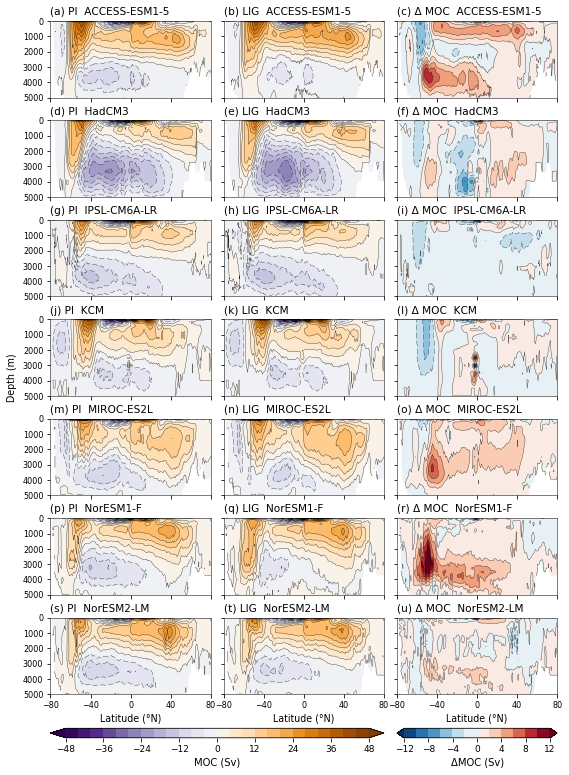

In [16]:
datasets   = [PI_GMOC_models2, LIG_GMOC_models2, diff_GMOC]
suffixes    = ['PI ', 'LIG ', 'Δ MOC ']
model_names = ['ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
letters = 'abcdefghijklmnopqrstu'

# contour levels
levels_abs  = np.arange(-48., 48. + 4., 4.)
levels_diff = np.arange(-12., 12. + 2., 2.)
col_levels  = [levels_abs, levels_abs, levels_diff]
col_cmaps   = ['PuOr_r', 'PuOr_r', 'RdBu_r']

nrows, ncols = len(model_names), len(datasets)

fig, axs = plt.subplots(nrows, ncols, figsize=(8, 11))
ims = [None] * ncols
for j, (simulations, levels, cmap) in enumerate(zip(datasets, col_levels, col_cmaps)):
    for n in range(nrows):
        ax = axs[n, j]
        ax.set_yticks(np.arange(0, 5000 + 1000, 1000))
        ax.set_xticks(np.arange(-80, 80 + 40, 40))
        ax.set_xlim([-80, 80])
        ax.set_ylim([0, 5000])
        
        # thin lines for subplot boxes
        for spine in ax.spines.values():
            spine.set_linewidth(0.5)

        # titles
        title = '({}) {} {}'.format(letters[n*ncols + j], suffixes[j], model_names[n])
        ax.set_title(title, fontsize=10.5, loc='left')

        show_depth = (j == 0)             # first column only
        show_lat   = (n == nrows - 1)     # bottom row only
        ax.tick_params(axis='y', labelsize=8, labelleft=show_depth)
        ax.tick_params(axis='x', labelsize=8, labelbottom=show_lat)
        if show_lat:
            ax.set_xlabel('Latitude (°N)', fontsize=9.5)

        depth_name = simulations[n].coord(dimensions=0).name()
        scale = 1.0E9 if n in (2, 4, 5, 6) else 1.0   # unit fix, as before
        cube = simulations[n] / scale if scale != 1.0 else simulations[n]

        ims[j] = iplt.contourf(cube, coords=['latitude', depth_name], levels=levels, cmap=cmap, extend='both', axes=ax)
        iplt.contour(cube, coords=['latitude', depth_name], levels=levels, colors='k', linewidths=0.3, axes=ax)
        if n == 3:
            ax.invert_yaxis()

plt.subplots_adjust(left=0.09, right=0.97, top=0.95, bottom=0.10, wspace=0.08, hspace=0.30)

fig.text(0.015, 0.5, 'Depth (m)', va='center', rotation='vertical', fontsize=9.5)

# Colourbars
p0, p1, p2 = (axs[-1, j].get_position() for j in range(3))
cb_h, cb_y = 0.012, 0.045

cax1 = fig.add_axes([p0.x0, cb_y, p1.x1 - p0.x0, cb_h])
cb1 = fig.colorbar(ims[0], cax=cax1, orientation='horizontal')
cb1.set_label('MOC (Sv)', fontsize=10)
cb1.ax.tick_params(labelsize=9)

cax2 = fig.add_axes([p2.x0, cb_y, p2.x1 - p2.x0, cb_h])
cb2 = fig.colorbar(ims[2], cax=cax2, orientation='horizontal')
cb2.set_label('ΔMOC (Sv)', fontsize=10)
cb2.ax.tick_params(labelsize=9)

#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/GMOC_PI_LIG_diff.png', dpi=300, bbox_inches='tight')
plt.show()

### AMOC

#### Setup

In [17]:
## Fix KCM lats PI
cube = PI_AMOC_models2[3]
#Remove only coords with no name
for c in cube.coords():
    if c.standard_name is None and c.long_name is None and c.var_name is None:
        print('removing', c)
        cube.remove_coord(c)
#Add latitude if there isn't one already
if not cube.coords('latitude'):
    lat = np.linspace(-90, 90, 149)   # placeholder, replace with real values
    cube.add_dim_coord(DimCoord(lat, standard_name='latitude', units='degrees'), 1)
#Fix depth
depth = cube.coord(dimensions=0)
depth.rename('depth')
if depth.points.mean() < 0:
    depth.points = -depth.points
    if depth.has_bounds():
        depth.bounds = -depth.bounds
depth.units = 'm'

In [18]:
## Fix KCM lats LIG
cube = LIG_AMOC_models2[3]
#Remove only coords with no name
for c in cube.coords():
    if c.standard_name is None and c.long_name is None and c.var_name is None:
        print('removing', c)
        cube.remove_coord(c)
#Add latitude if there isn't one already
if not cube.coords('latitude'):
    lat = np.linspace(-90, 90, 149)   # placeholder, replace with real values
    cube.add_dim_coord(DimCoord(lat, standard_name='latitude', units='degrees'), 1)
#Fix depth
depth = cube.coord(dimensions=0)
depth.rename('depth')
if depth.points.mean() < 0:
    depth.points = -depth.points
    if depth.has_bounds():
        depth.bounds = -depth.bounds
depth.units = 'm'                     # confirm these really are metres

#### Differences

In [19]:
titles = ['ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L','NorESM1-F', 'NorESM2-LM']
### Differences
diff_AMOC = []
for i in range (np.size(titles)):
    diff = LIG_AMOC_models2[i].data-PI_AMOC_models2[i].data
    diff_cube = PI_AMOC_models2[i].copy(data = diff)
    diff_AMOC.append(diff_cube)

#### Plot

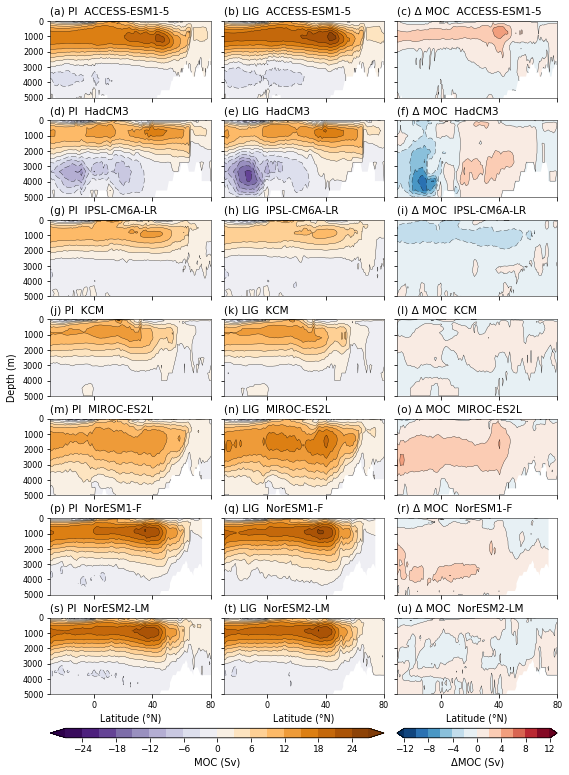

In [20]:
datasets   = [PI_AMOC_models2, LIG_AMOC_models2, diff_AMOC]
suffixes    = ['PI ', 'LIG ', 'Δ MOC ']
model_names = ['ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
letters = 'abcdefghijklmnopqrstu'
# contour levels
levels_abs  = np.arange(-27., 27.+3., 3.)
levels_diff = np.arange(-12., 12. + 2., 2.)
col_levels  = [levels_abs, levels_abs, levels_diff]
col_cmaps   = ['PuOr_r', 'PuOr_r', 'RdBu_r']

nrows, ncols = len(model_names), len(datasets)


fig, axs = plt.subplots(nrows, ncols, figsize=(8, 11))
ims = [None] * ncols
for j, (simulations, levels, cmap) in enumerate(zip(datasets, col_levels, col_cmaps)):
    for n in range(nrows):
        ax = axs[n, j]
        ax.set_yticks(np.arange(0, 5000 + 1000, 1000))
        ax.set_xticks(np.arange(-80, 80 + 40, 40))
        ax.set_xlim([-30, 80])
        ax.set_ylim([0, 5000])
        
        for spine in ax.spines.values():
            spine.set_linewidth(0.5)

        # title
        title = '({}) {} {}'.format(letters[n*ncols + j], suffixes[j], model_names[n])
        ax.set_title(title, fontsize=10.5, loc='left')

        show_depth = (j == 0)             # first column only
        show_lat   = (n == nrows - 1)     # bottom row
        ax.tick_params(axis='y', labelsize=8, labelleft=show_depth)
        ax.tick_params(axis='x', labelsize=8, labelbottom=show_lat)
        if show_lat:
            ax.set_xlabel('Latitude (°N)', fontsize=9.5)

        depth_name = simulations[n].coord(dimensions=0).name()
        scale = 1.0E9 if n in (2, 4, 5, 6) else 1.0   # unit fix, as before
        cube = simulations[n] / scale if scale != 1.0 else simulations[n]

        ims[j] = iplt.contourf(cube, coords=['latitude', depth_name], levels=levels, cmap=cmap, extend='both', axes=ax)
        iplt.contour(cube, coords=['latitude', depth_name], levels=levels, colors='k', linewidths=0.3, axes=ax)
        if n == 3:
            ax.invert_yaxis()

plt.subplots_adjust(left=0.09, right=0.97, top=0.95, bottom=0.10,
                    wspace=0.08, hspace=0.30)

fig.text(0.015, 0.5, 'Depth (m)', va='center', rotation='vertical', fontsize=9.5)

# Colourbars
p0, p1, p2 = (axs[-1, j].get_position() for j in range(3))
cb_h, cb_y = 0.012, 0.045

cax1 = fig.add_axes([p0.x0, cb_y, p1.x1 - p0.x0, cb_h])
cb1 = fig.colorbar(ims[0], cax=cax1, orientation='horizontal')
cb1.set_label('MOC (Sv)', fontsize=10)
cb1.ax.tick_params(labelsize=9)

cax2 = fig.add_axes([p2.x0, cb_y, p2.x1 - p2.x0, cb_h])
cb2 = fig.colorbar(ims[2], cax=cax2, orientation='horizontal')
cb2.set_label('ΔMOC (Sv)', fontsize=10)
cb2.ax.tick_params(labelsize=9)

#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/AMOC_PI_LIG_diff.png', dpi=300, bbox_inches='tight')
plt.show()

### IPMOC

In [21]:
## Fix KCM lats PI
cube = PI_IPMOC_models2[3]
#Remove only coords with no name
for c in cube.coords():
    if c.standard_name is None and c.long_name is None and c.var_name is None:
        print('removing', c)
        cube.remove_coord(c)
#Add latitude if there isn't one already
if not cube.coords('latitude'):
    lat = np.linspace(-90, 90, 149)
    cube.add_dim_coord(DimCoord(lat, standard_name='latitude', units='degrees'), 1)
#Fix depth
depth = cube.coord(dimensions=0)
depth.rename('depth')
if depth.points.mean() < 0:
    depth.points = -depth.points
    if depth.has_bounds():
        depth.bounds = -depth.bounds
depth.units = 'm'

In [22]:
## Fix KCM lats LIG
cube = LIG_IPMOC_models2[3]
#Remove only coords with no name
for c in cube.coords():
    if c.standard_name is None and c.long_name is None and c.var_name is None:
        print('removing', c)
        cube.remove_coord(c)
#Add latitude if there isn't one already
if not cube.coords('latitude'):
    lat = np.linspace(-90, 90, 149)   # placeholder, replace with real values
    cube.add_dim_coord(DimCoord(lat, standard_name='latitude', units='degrees'), 1)
#Fix depth
depth = cube.coord(dimensions=0)
depth.rename('depth')
if depth.points.mean() < 0:
    depth.points = -depth.points
    if depth.has_bounds():
        depth.bounds = -depth.bounds
depth.units = 'm'                     # confirm these really are metres

#### Differences

In [24]:
titles = ['ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L','NorESM1-F', 'NorESM2-LM']
### Differences
diff_IPMOC = []
for i in range (np.size(titles)):
    diff = LIG_IPMOC_models2[i].data-PI_IPMOC_models2[i].data
    diff_cube = PI_IPMOC_models2[i].copy(data = diff)
    diff_IPMOC.append(diff_cube)

#### Plot

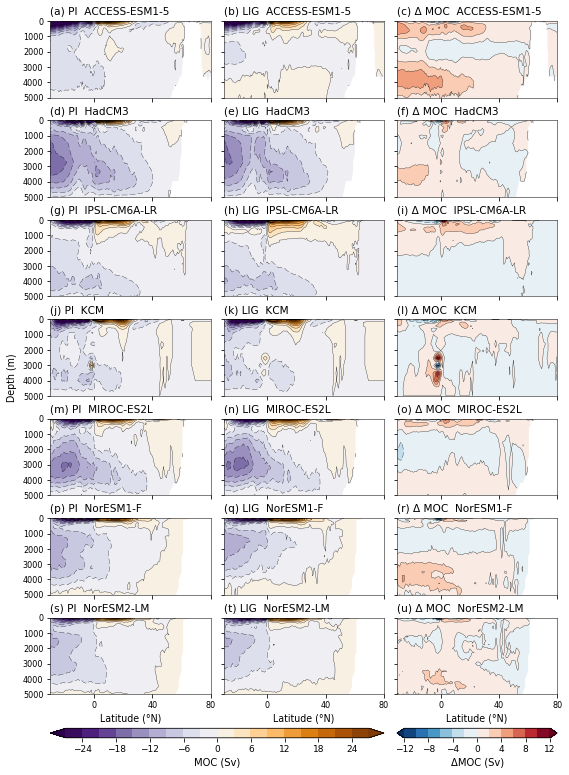

In [25]:
datasets   = [PI_IPMOC_models2, LIG_IPMOC_models2, diff_IPMOC]
suffixes    = ['PI ', 'LIG ', 'Δ MOC ']
model_names = ['ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
letters = 'abcdefghijklmnopqrstu'

# contour levels
levels_abs  = np.arange(-27., 27.+3., 3.)
levels_diff = np.arange(-12., 12. + 2., 2.)
col_levels  = [levels_abs, levels_abs, levels_diff]
col_cmaps   = ['PuOr_r', 'PuOr_r', 'RdBu_r']
nrows, ncols = len(model_names), len(datasets)

fig, axs = plt.subplots(nrows, ncols, figsize=(8, 11))
ims = [None] * ncols
for j, (simulations, levels, cmap) in enumerate(zip(datasets, col_levels, col_cmaps)):
    for n in range(nrows):
        ax = axs[n, j]
        ax.set_yticks(np.arange(0, 5000 + 1000, 1000))
        ax.set_xticks(np.arange(-80, 80 + 40, 40))
        ax.set_xlim([-30, 80])
        ax.set_ylim([0, 5000])
        
        for spine in ax.spines.values():
            spine.set_linewidth(0.5)

        # titles
        title = '({}) {} {}'.format(letters[n*ncols + j], suffixes[j], model_names[n])
        ax.set_title(title, fontsize=10.5, loc='left')

        show_depth = (j == 0)             # first column
        show_lat   = (n == nrows - 1)     # bottom row
        ax.tick_params(axis='y', labelsize=8, labelleft=show_depth)
        ax.tick_params(axis='x', labelsize=8, labelbottom=show_lat)
        if show_lat:
            ax.set_xlabel('Latitude (°N)', fontsize=9.5)

        depth_name = simulations[n].coord(dimensions=0).name()
        scale = 1.0E9 if n in (2, 4, 5, 6) else 1.0   # unit fix, as before
        cube = simulations[n] / scale if scale != 1.0 else simulations[n]

        ims[j] = iplt.contourf(cube, coords=['latitude', depth_name], levels=levels, cmap=cmap, extend='both', axes=ax)
        iplt.contour(cube, coords=['latitude', depth_name], levels=levels, colors='k', linewidths=0.3, axes=ax)
        if n == 3:
            ax.invert_yaxis()

plt.subplots_adjust(left=0.09, right=0.97, top=0.95, bottom=0.10,
                    wspace=0.08, hspace=0.30)
fig.text(0.015, 0.5, 'Depth (m)', va='center', rotation='vertical', fontsize=9.5)

# Colourbars
p0, p1, p2 = (axs[-1, j].get_position() for j in range(3))
cb_h, cb_y = 0.012, 0.045

cax1 = fig.add_axes([p0.x0, cb_y, p1.x1 - p0.x0, cb_h])
cb1 = fig.colorbar(ims[0], cax=cax1, orientation='horizontal')
cb1.set_label('MOC (Sv)', fontsize=10)
cb1.ax.tick_params(labelsize=9)

cax2 = fig.add_axes([p2.x0, cb_y, p2.x1 - p2.x0, cb_h])
cb2 = fig.colorbar(ims[2], cax=cax2, orientation='horizontal')
cb2.set_label('ΔMOC (Sv)', fontsize=10)
cb2.ax.tick_params(labelsize=9)

#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/IPMOC_PI_LIG_diff.png', dpi=300, bbox_inches='tight')
plt.show()